# Transit Equity Analysis: Who Madison Metro Actually Serves

## Project Description

In this project, I analyze **Madison Metro's GTFS transit data** alongside **U.S. Census demographic data** to investigate whether bus service frequency is distributed equitably across Madison neighborhoods. I compute a service-frequency score for 1,600+ bus stops and geospatially join each stop to its Census tract to bring in income, population, and vehicle-ownership data.

An initial version of the frequency metric was inflated — some circulator routes revisit the same stop twice per loop, double-counting service. I diagnosed this by comparing raw stop-visit counts to distinct trip counts and corrected the metric accordingly.

The results challenge a simple "poorer areas are underserved" assumption: transit access correlates **negatively** with median income (r = -0.45) and **positively** with car-free household rate (r = 0.71). This is likely because Madison's highest-frequency transit area sits on the UW–Madison campus/downtown isthmus, where students report low income despite living in the best-served part of the city, meaning proximity to campus, not income, appears to be the real driver of access.

-----------------------------------------

## 1. Load Madison Metro's GTFS Transit Data
Downloading the official GTFS feed published by the City of Madison — a standard zip of CSVs describing the entire bus system (stops, routes, trips, and scheduled stop times).

In [1]:
import requests
import zipfile
import os

URL = "http://transitdata.cityofmadison.com/GTFS/mmt_gtfs.zip"
os.makedirs("data/gtfs", exist_ok=True)

response = requests.get(URL)
with open("data/mmt_gtfs.zip", "wb") as f:
    f.write(response.content)

with zipfile.ZipFile("data/mmt_gtfs.zip", "r") as z:
    z.extractall("data/gtfs")

print("Done. Files:", os.listdir("data/gtfs"))

Done. Files: ['agency.txt', 'calendar.txt', 'calendar_dates.txt', 'extended_data_dictionary.txt', 'fare_attributes.txt', 'fare_capping.txt', 'fare_leg_rules.txt', 'fare_media.txt', 'fare_products.txt', 'fare_rules.txt', 'fare_transfer_rules.txt', 'feed_info.txt', 'frequencies.txt', 'linked_datasets.txt', 'rider_categories.txt', 'routes.txt', 'shapes.txt', 'stops.txt', 'stop_features.txt', 'stop_times.txt', 'terms_of_use.txt', 'transfers.txt', 'translations.txt', 'trips.txt']


### Exploring the raw tables
Before building any logic, inspecting the five core GTFS tables and how they relate: `stops` (where), `routes` (which line), `trips` (a specific scheduled run), `stop_times` (when a trip hits each stop), and `calendar` (which days a schedule pattern is active).

In [2]:
import pandas as pd

stops = pd.read_csv("data/gtfs/stops.txt")
routes = pd.read_csv("data/gtfs/routes.txt")
trips = pd.read_csv("data/gtfs/trips.txt")
stop_times = pd.read_csv("data/gtfs/stop_times.txt")
calendar = pd.read_csv("data/gtfs/calendar.txt")

for name, df in [("stops", stops), ("routes", routes), ("trips", trips),
                  ("stop_times", stop_times), ("calendar", calendar)]:
    print(name, df.shape)
    print(df.head(2))
    print()

stops (1681, 19)
   stop_id stop_code                  stop_name  \
0        1      0010          Langdon at N Park   
1        3      E100  E Washington at East High   

                                           stop_desc   stop_lat   stop_lon  \
0  This stop (#0010) is westbound on the 898 bloc...  43.075933 -89.400154   
1  This flag stop (#E100) is westbound on the 222...  43.096625 -89.353789   

   zone_id  stop_url  location_type  parent_station  stop_timezone  \
0        1       NaN              0             NaN            NaN   
1        1       NaN              0             NaN            NaN   

   wheelchair_boarding  sign_type jurisdiction_id  relative_position  \
0                    1          1            CMAD                  3   
1                    1          0            CMAD                  2   

   cardinal_direction primary_street  address_range cross_location  
0               270.0        Langdon            898         N Park  
1               270.0   E Wa

## 2. Compute Stop-Level Service Frequency
Joining `stop_times` → `trips` → `calendar` to tag every stop visit with the day of week it belongs to, then filtering to Wednesday as a representative weekday (avoids weekend service and Friday's slightly different schedule).

In [3]:
st_trips = stop_times.merge(trips[["trip_id", "route_id", "service_id"]], on="trip_id", how="left")

st_full = st_trips.merge(calendar, on="service_id", how="left")

weekday_stops = st_full[st_full["wednesday"] == 1].copy()

print(weekday_stops.shape)
weekday_stops.head()

(200240, 21)


,trip_id,arrival_time,departure_time,stop_id,stop_sequence,stop_headsign,pickup_type,drop_off_type,shape_dist_traveled,timepoint,...,service_id,monday,tuesday,wednesday,thursday,friday,saturday,sunday,start_date,end_date
0,1020,15:49:00,15:49:00,3,1,602-E TOWNE,0,1,0.00,1,...,9,1,1,1,1,0,0,0,20260816,20261205
1,1020,15:58:00,15:58:00,2154,2,602-E TOWNE,0,0,5262.60,1,...,9,1,1,1,1,0,0,0,20260816,20261205
2,1020,15:59:51,15:59:51,2172,3,602-E TOWNE,1,0,5948.64,0,...,9,1,1,1,1,0,0,0,20260816,20261205
3,1020,16:00:42,16:00:42,2100,4,602-E TOWNE,1,0,6326.49,0,...,9,1,1,1,1,0,0,0,20260816,20261205
4,1020,16:01:20,16:01:20,2772,5,602-E TOWNE,1,0,6616.87,0,...,9,1,1,1,1,0,0,0,20260816,20261205


Converting GTFS's raw `HH:MM:SS` arrival times into an hour-of-day value. Note: GTFS times can exceed `24:00:00` for overnight trips, so hours are collapsed into the normal 0–23 range.

In [4]:
def parse_gtfs_time_to_hour(t):
    h, m, s = t.split(":")
    return int(h) % 24 

weekday_stops["hour"] = weekday_stops["arrival_time"].apply(parse_gtfs_time_to_hour)

In [5]:
service_window = weekday_stops[(weekday_stops["hour"] >= 6) & (weekday_stops["hour"] < 22)]

### Building the frequency metric
Counting **distinct trips** per stop rather than raw stop-time rows — an earlier version of this used raw row counts and produced implausibly high numbers (~60 trips/hour) at some stops. Investigation showed circulator routes (e.g., Route 80) pass the same physical stop twice per loop, inflating row counts without reflecting real additional service. Switching to distinct trip counts corrected this.

In [6]:
trip_counts = service_window.groupby("stop_id")["trip_id"].nunique().reset_index(name="total_trips")
trip_counts["trips_per_hour"] = trip_counts["total_trips"] / 16

trip_counts.sort_values("trips_per_hour", ascending=False).head(10)

,stop_id,total_trips,trips_per_hour
308,709,990,61.8750
1495,2810,873,54.5625
325,741,800,50.0000
634,1262,786,49.1250
262,616,786,49.1250
593,1185,786,49.1250
267,628,741,46.3125
434,918,735,45.9375
301,692,720,45.0000
411,882,698,43.6250


## 3. Pull Census Demographic Data
Loading the Census API key from a `.env` file (kept out of version control) and fetching ACS 5-year estimates — population, median income, and vehicle-ownership data — for every census tract in Dane County.

In [7]:
from dotenv import load_dotenv
import os

load_dotenv()
CENSUS_API_KEY = os.getenv("CENSUS_API_KEY")
print("Key loaded:", CENSUS_API_KEY is not None)

Key loaded: True


In [8]:
variables = "B01003_001E,B19013_001E,B25044_001E,B25044_003E,B25044_010E"

url = (
    f"https://api.census.gov/data/2022/acs/acs5"
    f"?get={variables}"
    f"&for=tract:*&in=state:55+county:025"
    f"&key={CENSUS_API_KEY}"
)

response = requests.get(url)
data = response.json()

census_df = pd.DataFrame(data[1:], columns=data[0])
print(census_df.shape)
census_df.head()

(125, 8)


,B01003_001E,B19013_001E,B25044_001E,B25044_003E,B25044_010E,state,county,tract
0,2453,81738,1359,9,82,55,025,000100
1,2329,97946,1093,9,33,55,025,000201
2,3281,96964,1421,23,29,55,025,000202
3,5643,86417,2562,19,146,55,025,000204
4,4967,97539,2525,15,58,55,025,000205


In [9]:
value_cols = ["B01003_001E", "B19013_001E", "B25044_001E", "B25044_003E", "B25044_010E"]
for col in value_cols:
    census_df[col] = pd.to_numeric(census_df[col], errors="coerce")

census_df[value_cols] = census_df[value_cols].where(census_df[value_cols] > -1, None)

census_df = census_df.rename(columns={
    "B01003_001E": "population",
    "B19013_001E": "median_income",
    "B25044_001E": "total_households",
    "B25044_003E": "owner_no_vehicle",
    "B25044_010E": "renter_no_vehicle"
})

census_df["GEOID"] = census_df["state"] + census_df["county"] + census_df["tract"]

census_df["pct_no_vehicle"] = (
    (census_df["owner_no_vehicle"] + census_df["renter_no_vehicle"]) / census_df["total_households"]
) * 100

census_df[["GEOID", "population", "median_income", "pct_no_vehicle"]].head()

,GEOID,population,median_income,pct_no_vehicle
0,55025000100,2453,81738.0,6.696100
1,55025000201,2329,97946.0,3.842635
2,55025000202,3281,96964.0,3.659395
3,55025000204,5643,86417.0,6.440281
4,55025000205,4967,97539.0,2.891089


In [1]:
#import sys
#!"{sys.executable}" -m pip install geopandas

## 4. Geospatial Join: Match Stops to Census Tracts
Downloading Census TIGER/Line tract boundary shapefiles for Wisconsin — the actual polygon geometry needed to determine which tract each bus stop physically falls inside.

In [11]:
import geopandas as gpd

shapefile_url = "https://www2.census.gov/geo/tiger/TIGER2022/TRACT/tl_2022_55_tract.zip"

tracts = gpd.read_file(shapefile_url)
print(tracts.shape)
tracts[["GEOID", "geometry"]].head()

(1542, 13)


,GEOID,geometry
0,55009940002,"POLYGON ((-88.15018 44.51202, -88.1501 44.5139..."
1,55009001600,"POLYGON ((-87.99468 44.48806, -87.99463 44.488..."
2,55009001801,"POLYGON ((-87.95519 44.51945, -87.95512 44.519..."
3,55009001802,"POLYGON ((-88.0075 44.53416, -88.00528 44.5384..."
4,55013970700,"POLYGON ((-92.5531 45.94872, -92.55302 45.9488..."


In [12]:
dane_tracts = tracts[tracts["GEOID"].str.startswith("55025")].copy()
print(dane_tracts.shape)

(125, 13)


In [15]:
from shapely.geometry import Point

stops_geo = gpd.GeoDataFrame(
    stops,
    geometry=[Point(lon, lat) for lon, lat in zip(stops["stop_lon"], stops["stop_lat"])],
    crs="EPSG:4326" 
)

### Running the spatial join
Performing a point-in-polygon join to match each bus stop to its census tract.

**Note:** this first attempt triggered a coordinate reference system (CRS) mismatch warning — stops were in WGS84 (`EPSG:4326`) while the tract shapefile was in NAD83 (`EPSG:4269`), two slightly different models of the Earth's shape. Fixed in the next cell by reprojecting before joining.

In [21]:
stops_with_tract = gpd.sjoin(stops_geo, dane_tracts[["GEOID", "geometry"]], how="left", predicate="within")
print(stops_with_tract.shape)
stops_with_tract[["stop_id", "stop_name", "GEOID"]].head(10)

(1681, 22)


,stop_id,stop_name,GEOID
0,1,Langdon at N Park,55025001102
1,3,E Washington at East High,55025002100
2,5,Regent at West High,55025000902
3,6,Regent at West High,55025000901
4,10,S Gammon at Memorial High,55025000202
5,11,Mid Town at Province Hill,55025000504
6,12,S Park at W Olin,55025001300
7,13,Pflaum at Lafollette High,55025002900
8,17,E Mifflin at N Pinckney,55025001706
9,18,W Main at M L K Junior,55025001704


In [22]:
dane_tracts = dane_tracts.to_crs("EPSG:4326")

stops_with_tract = gpd.sjoin(stops_geo, dane_tracts[["GEOID", "geometry"]], how="left", predicate="within")
print(stops_with_tract.shape)
print("NaN GEOIDs:", stops_with_tract["GEOID"].isna().sum())
stops_with_tract[["stop_id", "stop_name", "GEOID"]].head(10)

(1681, 22)
NaN GEOIDs: 0


,stop_id,stop_name,GEOID
0,1,Langdon at N Park,55025001102
1,3,E Washington at East High,55025002100
2,5,Regent at West High,55025000902
3,6,Regent at West High,55025000901
4,10,S Gammon at Memorial High,55025000202
5,11,Mid Town at Province Hill,55025000504
6,12,S Park at W Olin,55025001300
7,13,Pflaum at Lafollette High,55025002900
8,17,E Mifflin at N Pinckney,55025001706
9,18,W Main at M L K Junior,55025001704


In [23]:
stop_freq_with_tract = trip_counts.merge(
    stops_with_tract[["stop_id", "GEOID"]], on="stop_id", how="left"
)

tract_access = stop_freq_with_tract.groupby("GEOID")["trips_per_hour"].mean().reset_index()
tract_access = tract_access.rename(columns={"trips_per_hour": "avg_trips_per_hour"})

print(tract_access.shape)
tract_access.sort_values("avg_trips_per_hour", ascending=False).head(10)

(94, 2)


,GEOID,avg_trips_per_hour
25,55025001102,31.974537
34,55025001603,23.015625
40,55025001707,19.650000
62,55025003200,19.448214
24,55025001101,18.323529
39,55025001706,17.781250
49,55025002302,17.218750
37,55025001606,16.772321
38,55025001704,16.453125
43,55025001901,15.363971


In [24]:
final_df = tract_access.merge(census_df, on="GEOID", how="inner")
print(final_df.shape)
final_df[["GEOID", "avg_trips_per_hour", "median_income", "pct_no_vehicle", "population"]].sort_values("median_income").head(10)

(94, 11)


,GEOID,avg_trips_per_hour,median_income,pct_no_vehicle,population
34,55025001603,23.015625,11826.0,59.015639,5203
24,55025001101,18.323529,16510.0,46.794872,5349
37,55025001606,16.772321,22766.0,42.159144,8418
35,55025001604,11.333333,24488.0,53.434471,6069
25,55025001102,31.974537,29583.0,54.166667,3756
11,55025000408,7.102823,39315.0,30.753283,2022
52,55025002500,5.265086,40854.0,10.644258,2145
22,55025000902,9.891827,41098.0,21.722986,6188
62,55025003200,19.448214,43261.0,23.255814,2662
5,55025000301,10.434211,44821.0,21.070518,3705


## 5. Findings
Testing whether transit access relates to income and vehicle ownership.

In [25]:
correlation = final_df["median_income"].corr(final_df["avg_trips_per_hour"])
print("Correlation (income vs. access):", correlation)

correlation2 = final_df["pct_no_vehicle"].corr(final_df["avg_trips_per_hour"])
print("Correlation (no-vehicle % vs. access):", correlation2)

Correlation (income vs. access): -0.45473658145288975
Correlation (no-vehicle % vs. access): 0.7073157585224694


### Visualizing the relationships

**Result:** transit access correlates *negatively* with median income (r ≈ -0.45) and strongly *positively* with car-free household rate (r ≈ 0.71) — the opposite of a simple "poor areas are underserved" hypothesis. This is likely explained by UW–Madison's student population: students report low income on Census surveys but live in the densest, highest-frequency transit area (campus/downtown), confounding a naive income-based equity read.

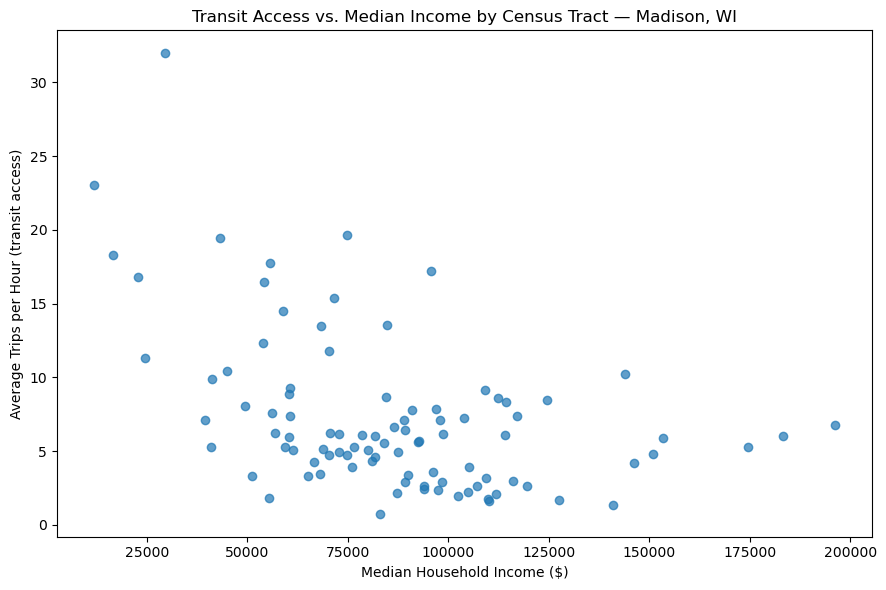

In [26]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(final_df["median_income"], final_df["avg_trips_per_hour"], alpha=0.7)
ax.set_xlabel("Median Household Income ($)")
ax.set_ylabel("Average Trips per Hour (transit access)")
ax.set_title("Transit Access vs. Median Income by Census Tract — Madison, WI")

plt.tight_layout()
plt.savefig("income_vs_access.png", dpi=150)
plt.show()

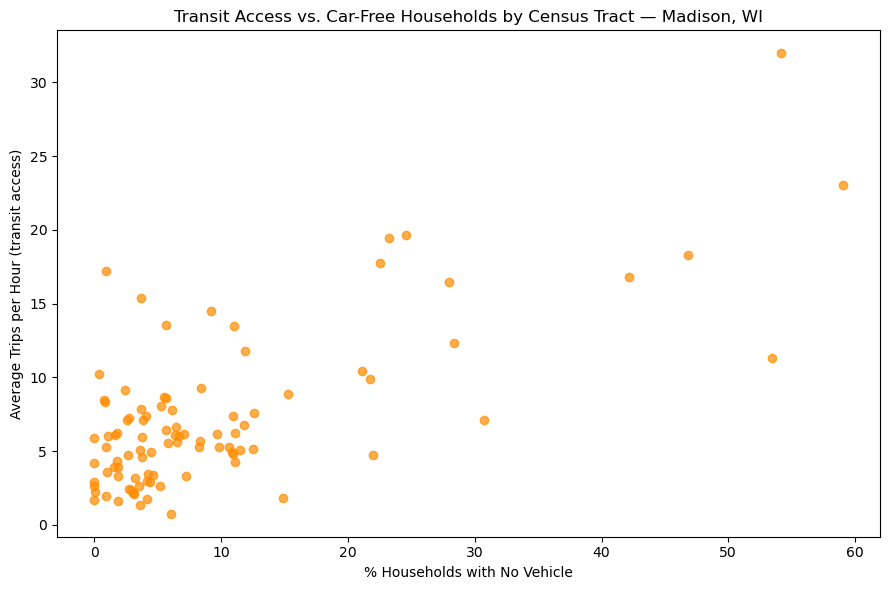

In [27]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(final_df["pct_no_vehicle"], final_df["avg_trips_per_hour"], alpha=0.7, color="darkorange")
ax.set_xlabel("% Households with No Vehicle")
ax.set_ylabel("Average Trips per Hour (transit access)")
ax.set_title("Transit Access vs. Car-Free Households by Census Tract — Madison, WI")

plt.tight_layout()
plt.savefig("novehicle_vs_access.png", dpi=150)
plt.show()

(94, 23)


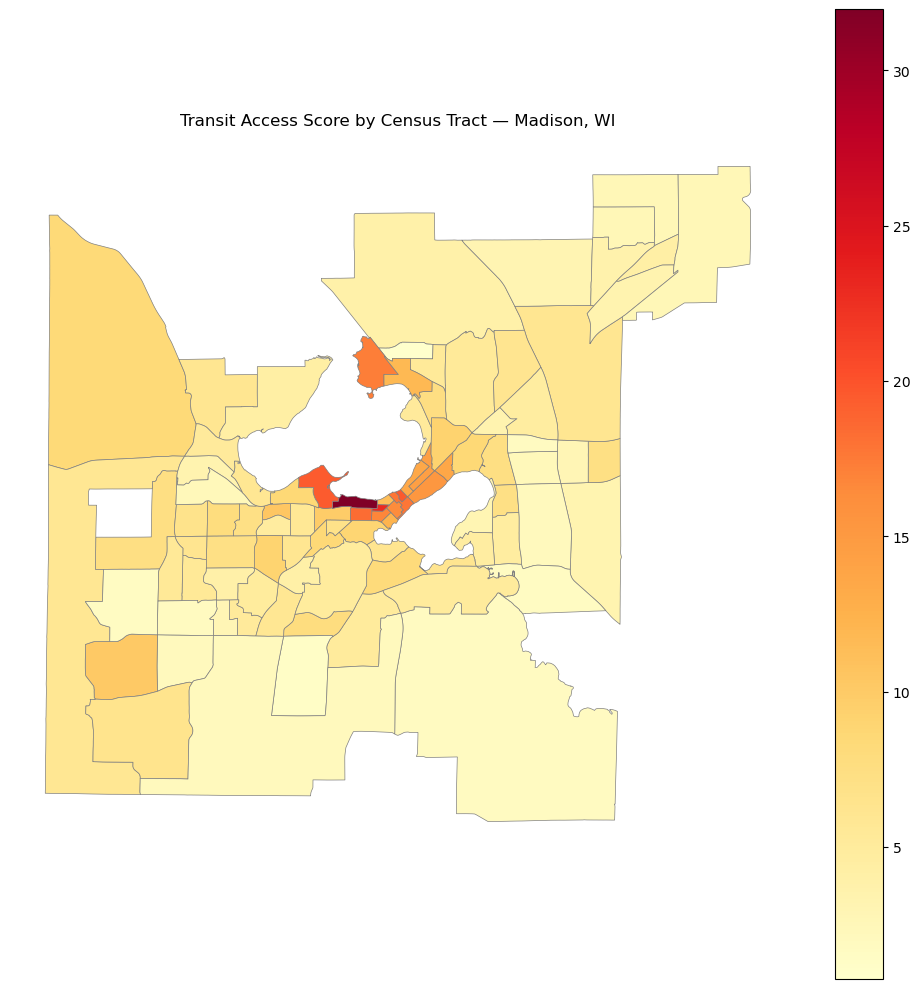

In [28]:
map_df = dane_tracts.merge(final_df, on="GEOID", how="inner")
print(map_df.shape)

fig, ax = plt.subplots(figsize=(10, 10))
map_df.plot(
    column="avg_trips_per_hour",
    cmap="YlOrRd",
    linewidth=0.5,
    edgecolor="gray",
    legend=True,
    ax=ax
)
ax.set_title("Transit Access Score by Census Tract — Madison, WI")
ax.axis("off")

plt.tight_layout()
plt.savefig("transit_access_map.png", dpi=150)
plt.show()